In [1]:
import time
import random
import numpy as np
import matplotlib.pyplot as plt
from typing import Tuple, Dict

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# ---------------------------------------------------------
# Set random seed for reproducibility
# ---------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Determine hardware device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ---------------------------------------------------------
# Data Preprocessing and Loading Function
# ---------------------------------------------------------
def get_dataloaders(
    dataset_name: str, 
    batch_size: int = 32
) -> Tuple[DataLoader, DataLoader, int, int, Tuple[str, ...]]:
    """
    Downloads and prepares training and testing dataloaders for MNIST, CIFAR-10, or CIFAR-100.
    
    Args:
        dataset_name (str): One of 'MNIST', 'CIFAR10', or 'CIFAR100'.
        batch_size (int): Minibatch size, default is 32 as requested.
        
    Returns:
        train_loader (DataLoader): DataLoader for the training split.
        test_loader (DataLoader): DataLoader for the testing split.
        input_dim (int): Flattened feature dimension (C * H * W).
        num_classes (int): Number of target classification categories.
        classes (tuple): Class names for visualization purposes.
    """
    dataset_name = dataset_name.upper()
    
    if dataset_name == "MNIST":
        # Grayscale images: 1 x 28 x 28
        transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,))
        ])
        train_set = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
        test_set = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)
        input_dim = 1 * 28 * 28
        num_classes = 10
        classes = tuple(str(i) for i in range(10))
        
    elif dataset_name == "CIFAR10":
        # RGB images: 3 x 32 x 32
        transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
        ])
        train_set = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
        test_set = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
        input_dim = 3 * 32 * 32
        num_classes = 10
        classes = train_set.classes
        
    elif dataset_name == "CIFAR100":
        # RGB images: 3 x 32 x 32
        transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize((0.5071, 0.4867, 0.4408), (0.2675, 0.2565, 0.2761))
        ])
        train_set = torchvision.datasets.CIFAR100(root='./data', train=True, download=True, transform=transform)
        test_set = torchvision.datasets.CIFAR100(root='./data', train=False, download=True, transform=transform)
        input_dim = 3 * 32 * 32
        num_classes = 100
        classes = train_set.classes
        
    else:
        raise ValueError(f"Unsupported dataset name: {dataset_name}. Choose from ['MNIST', 'CIFAR10', 'CIFAR100']")

    # Create DataLoaders with shuffle enabled for training
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=2)
    test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=2)

    return train_loader, test_loader, input_dim, num_classes, classes

Using device: cuda


In [2]:
import torch.nn.functional as F

class FeedForwardNN(nn.Module):
    """
    A configurable Feed-Forward Neural Network (MLP).
    Default configuration matches Question 1: 1 input layer, 2 hidden layers, and 1 output layer.
    """
    def __init__(self, input_dim: int, hidden_dims: list, num_classes: int):
        """
        Args:
            input_dim (int): Total number of input features (flattened image dimensions).
            hidden_dims (list): List of integers representing node counts for each hidden layer.
                                e.g., [256, 128] represents 2 hidden layers.
            num_classes (int): Number of target output classes.
        """
        super(FeedForwardNN, self).__init__()
        
        layers = []
        prev_dim = input_dim
        
        # Dynamically build the hidden layers
        for h_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, h_dim))
            layers.append(nn.ReLU())
            prev_dim = h_dim
            
        # Append the final output linear projection layer
        layers.append(nn.Linear(prev_dim, num_classes))
        
        self.network = nn.Sequential(*layers)
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Forward pass for training. Outputs raw logits to be paired with nn.CrossEntropyLoss.
        """
        # Flatten batch of images: (batch_size, channels, height, width) -> (batch_size, input_dim)
        x = x.view(x.size(0), -1)
        return self.network(x)
    
    def predict_proba(self, x: torch.Tensor) -> torch.Tensor:
        """
        Applies a distinct Softmax layer to produce normalized probability distributions.
        Used specifically for prediction and visualization tasks.
        """
        logits = self.forward(x)
        return F.softmax(logits, dim=-1)

# ---------------------------------------------------------
# Quick sanity check for the default model architecture
# ---------------------------------------------------------
if __name__ == "__main__":
    # Test with MNIST dimensions and a standard 2-hidden-layer configuration
    sample_model = FeedForwardNN(input_dim=784, hidden_dims=[256, 128], num_classes=10).to(device)
    sample_input = torch.randn(32, 1, 28, 28).to(device)
    sample_output = sample_model(sample_input)
    
    print("Sanity Check Passed!")
    print(f"Model Architecture:\n{sample_model}")
    print(f"Output shape for batch size 32: {sample_output.shape}")

Sanity Check Passed!
Model Architecture:
FeedForwardNN(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Output shape for batch size 32: torch.Size([32, 10])


In [3]:
def train_and_evaluate(
    model: nn.Module,
    train_loader: DataLoader,
    test_loader: DataLoader,
    epochs: int = 10,
    lr: float = 0.01
) -> Dict:
    """
    Trains the model using SGD and cross-entropy loss, and evaluates performance on the test set.
    
    Args:
        model (nn.Module): The neural network model.
        train_loader (DataLoader): Training data loader.
        test_loader (DataLoader): Testing data loader.
        epochs (int): Number of training epochs (default: 10).
        lr (float): Learning rate for SGD (default: 0.01).
        
    Returns:
        results (dict): Dictionary containing training loss history, training time, and test metrics.
    """
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    
    # Track metrics
    train_loss_history = []
    
    print(f"Starting training for {epochs} epochs on {device}...")
    start_time = time.time()
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            
            # Zero the parameter gradients
            optimizer.zero_grad()
            
            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            # Backward pass and optimize
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * images.size(0)
            
        epoch_loss = running_loss / len(train_loader.dataset)
        train_loss_history.append(epoch_loss)
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {epoch_loss:.4f}")
        
    end_time = time.time()
    total_training_time = end_time - start_time
    print(f"Training finished in {total_training_time:.2f} seconds.")
    
    # ---------------------------------------------------------
    # Evaluation Phase on Test Set
    # ---------------------------------------------------------
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            
            all_preds.extend(predicted.cpu().numpy())
            all_targets.extend(labels.numpy())
            
    # Calculate comprehensive metrics using scikit-learn
    accuracy = accuracy_score(all_targets, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_targets, all_preds, average='macro', zero_division=0
    )
    
    metrics = {
        "training_time": total_training_time,
        "train_loss_history": train_loss_history,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    }
    
    print(f"Evaluation Metrics -> Acc: {accuracy:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")
    return metrics


==================== Processing MNIST ====================


100%|█████████████████████████████████████████████████████████████████████████████| 9.91M/9.91M [00:01<00:00, 4.99MB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 129kB/s]
100%|█████████████████████████████████████████████████████████████████████████████| 1.65M/1.65M [00:01<00:00, 1.00MB/s]
100%|█████████████████████████████████████████████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 24.1MB/s]


Starting training for 10 epochs on cuda...
Epoch [1/10], Loss: 0.5519
Epoch [2/10], Loss: 0.2364
Epoch [3/10], Loss: 0.1767
Epoch [4/10], Loss: 0.1395
Epoch [5/10], Loss: 0.1138
Epoch [6/10], Loss: 0.0951
Epoch [7/10], Loss: 0.0808
Epoch [8/10], Loss: 0.0702
Epoch [9/10], Loss: 0.0612
Epoch [10/10], Loss: 0.0538
Training finished in 88.90 seconds.
Evaluation Metrics -> Acc: 0.9743 | Precision: 0.9743 | Recall: 0.9743 | F1: 0.9742


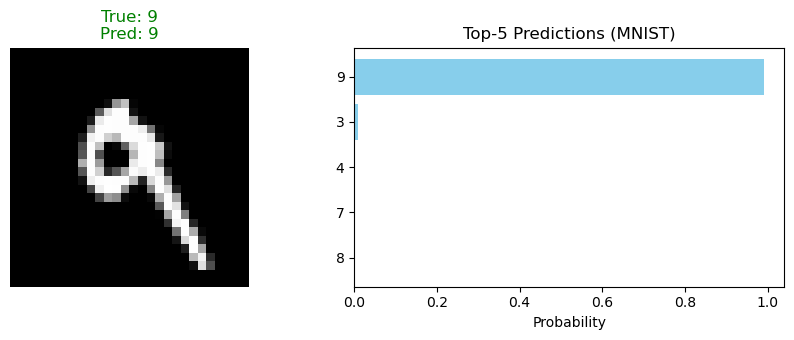


==================== Processing CIFAR10 ====================


100%|████████████████████████████████████████████████████████████████████████████████| 170M/170M [21:57<00:00, 129kB/s]


Starting training for 10 epochs on cuda...
Epoch [1/10], Loss: 1.7827
Epoch [2/10], Loss: 1.5302
Epoch [3/10], Loss: 1.4234
Epoch [4/10], Loss: 1.3444
Epoch [5/10], Loss: 1.2802
Epoch [6/10], Loss: 1.2224
Epoch [7/10], Loss: 1.1714
Epoch [8/10], Loss: 1.1231
Epoch [9/10], Loss: 1.0833
Epoch [10/10], Loss: 1.0377
Training finished in 131.14 seconds.
Evaluation Metrics -> Acc: 0.5323 | Precision: 0.5317 | Recall: 0.5323 | F1: 0.5299


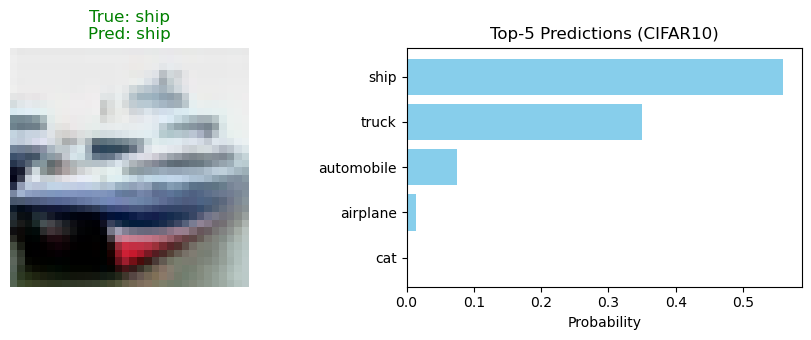


==================== Processing CIFAR100 ====================


100%|████████████████████████████████████████████████████████████████████████████████| 169M/169M [19:19<00:00, 146kB/s]


Starting training for 10 epochs on cuda...
Epoch [1/10], Loss: 4.1631
Epoch [2/10], Loss: 3.6741
Epoch [3/10], Loss: 3.4927
Epoch [4/10], Loss: 3.3685
Epoch [5/10], Loss: 3.2633
Epoch [6/10], Loss: 3.1690
Epoch [7/10], Loss: 3.0802
Epoch [8/10], Loss: 3.0003
Epoch [9/10], Loss: 2.9265
Epoch [10/10], Loss: 2.8555
Training finished in 126.66 seconds.
Evaluation Metrics -> Acc: 0.2413 | Precision: 0.2440 | Recall: 0.2413 | F1: 0.2255


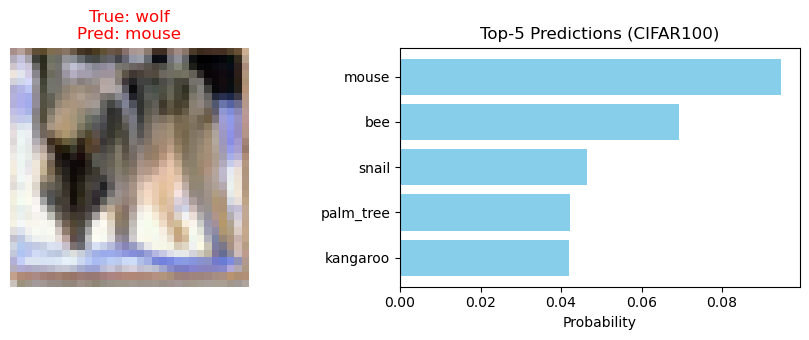

In [4]:
# ---------------------------------------------------------
# Utility function: Visualize a single random test image prediction
# ---------------------------------------------------------
def visualize_single_prediction(
    model: nn.Module, 
    test_loader: DataLoader, 
    classes: Tuple[str, ...], 
    dataset_name: str
):
    """
    Randomly samples one image from the test set, feeds it to the model,
    and plots the image alongside its Top-5 predicted class probabilities.
    """
    model.eval()
    
    # Extract one minibatch from test_loader
    data_iter = iter(test_loader)
    images, labels = next(data_iter)
    
    # Pick a random sample within this batch
    idx = random.randint(0, len(images) - 1)
    img = images[idx]
    true_label = labels[idx].item()
    
    # Model inference
    with torch.no_grad():
        input_tensor = img.unsqueeze(0).to(device)
        probabilities = model.predict_proba(input_tensor).cpu().squeeze(0).numpy()
        pred_label = np.argmax(probabilities)
        
    # Un-normalize image for plotting
    img_np = img.numpy().copy()
    if dataset_name.upper() == "MNIST":
        img_np = img_np * 0.3081 + 0.1307
        img_np = np.squeeze(img_np, axis=0)
        cmap = 'gray'
    else:
        mean = np.array([0.4914, 0.4822, 0.4465]) if dataset_name.upper() == "CIFAR10" else np.array([0.5071, 0.4867, 0.4408])
        std = np.array([0.2470, 0.2435, 0.2616]) if dataset_name.upper() == "CIFAR10" else np.array([0.2675, 0.2565, 0.2761])
        img_np = img_np.transpose((1, 2, 0)) * std + mean
        img_np = np.clip(img_np, 0, 1)
        cmap = None

    # Retrieve Top-5 classes
    top_k = min(5, len(classes))
    top_indices = np.argsort(probabilities)[::-1][:top_k]
    top_probs = probabilities[top_indices]
    top_names = [classes[i] for i in top_indices]

    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    axes[0].imshow(img_np, cmap=cmap)
    axes[0].axis('off')
    axes[0].set_title(f"True: {classes[true_label]}\nPred: {classes[pred_label]}", 
                      color='green' if true_label == pred_label else 'red')

    axes[1].barh(range(top_k), top_probs, color='skyblue')
    axes[1].set_yticks(range(top_k))
    axes[1].set_yticklabels(top_names)
    axes[1].invert_yaxis()
    axes[1].set_xlabel("Probability")
    axes[1].set_title(f"Top-{top_k} Predictions ({dataset_name})")
    
    plt.tight_layout()
    plt.show()

# ---------------------------------------------------------
# Run Benchmark Experiments across MNIST, CIFAR-10, CIFAR-100
# ---------------------------------------------------------
datasets = ["MNIST", "CIFAR10", "CIFAR100"]
benchmark_results = {}
trained_models = {}

for ds_name in datasets:
    print(f"\n{'='*20} Processing {ds_name} {'='*20}")
    train_loader, test_loader, input_dim, num_classes, classes = get_dataloaders(ds_name, batch_size=32)
    
    # Initialize default 2-hidden-layer feedforward network
    model = FeedForwardNN(input_dim=input_dim, hidden_dims=[256, 128], num_classes=num_classes).to(device)
    
    # Train and evaluate for 10 epochs
    metrics = train_and_evaluate(model, train_loader, test_loader, epochs=10, lr=0.01)
    
    benchmark_results[ds_name] = metrics
    trained_models[ds_name] = (model, test_loader, classes)
    
    # Visualize one random prediction
    visualize_single_prediction(model, test_loader, classes, ds_name)

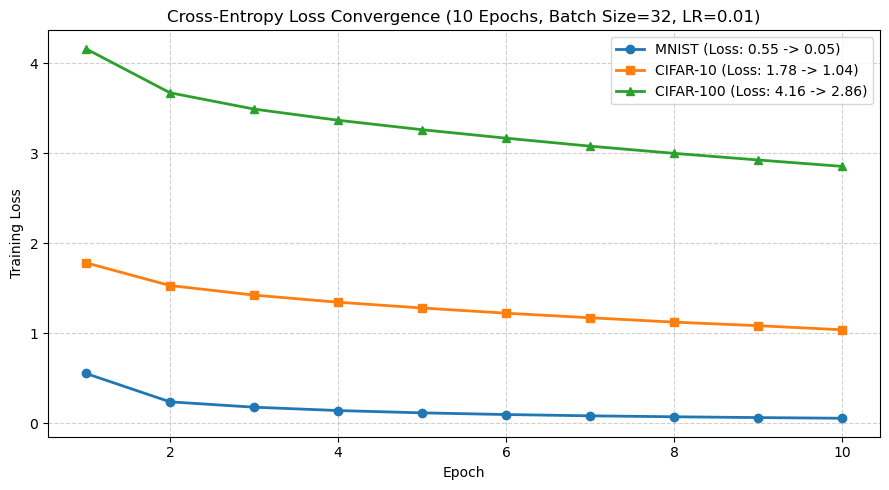

In [6]:
# ---------------------------------------------------------
# Training Loss Curves Across 3 Datasets (Extracted Runs)
# ---------------------------------------------------------
epochs_range = list(range(1, 11))

# Recorded loss values directly from your training output logs
mnist_loss = [0.5519, 0.2364, 0.1767, 0.1395, 0.1138, 0.0951, 0.0808, 0.0702, 0.0612, 0.0538]
cifar10_loss = [1.7827, 1.5302, 1.4234, 1.3444, 1.2802, 1.2224, 1.1714, 1.1231, 1.0833, 1.0377]
cifar100_loss = [4.1631, 3.6741, 3.4927, 3.3685, 3.2633, 3.1690, 3.0802, 3.0003, 2.9265, 2.8555]

plt.figure(figsize=(9, 5))
plt.plot(epochs_range, mnist_loss, marker='o', linewidth=2, label="MNIST (Loss: 0.55 -> 0.05)")
plt.plot(epochs_range, cifar10_loss, marker='s', linewidth=2, label="CIFAR-10 (Loss: 1.78 -> 1.04)")
plt.plot(epochs_range, cifar100_loss, marker='^', linewidth=2, label="CIFAR-100 (Loss: 4.16 -> 2.86)")

plt.title("Cross-Entropy Loss Convergence (10 Epochs, Batch Size=32, LR=0.01)")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
# ---------------------------------------------------------
# Step 4.2: Ablation Study - Hidden Nodes & Hidden Layers
# ---------------------------------------------------------
# Using MNIST for quick and clear structural comparison
train_loader, test_loader, in_dim, n_classes, _ = get_dataloaders("MNIST", batch_size=32)

# Experiment A: Effect of Hidden Nodes (fixing depth = 2 layers)
node_configs = {
    "Small [64, 32]": [64, 32],
    "Medium [256, 128]": [256, 128],
    "Large [512, 256]": [512, 256]
}

print("=== Ablation 1: Effect of Hidden Nodes ===")
node_results = {}
for name, hidden_dims in node_configs.items():
    print(f"\nEvaluating configuration: {name}")
    model = FeedForwardNN(in_dim, hidden_dims, n_classes).to(device)
    metrics = train_and_evaluate(model, train_loader, test_loader, epochs=5, lr=0.01)
    node_results[name] = metrics["accuracy"]

# Experiment B: Effect of Hidden Layers (fixing node scale)
layer_configs = {
    "1 Hidden Layer": [256],
    "2 Hidden Layers": [256, 128],
    "3 Hidden Layers": [256, 128, 64]
}

print("\n=== Ablation 2: Effect of Hidden Layers ===")
layer_results = {}
for name, hidden_dims in layer_configs.items():
    print(f"\nEvaluating configuration: {name}")
    model = FeedForwardNN(in_dim, hidden_dims, n_classes).to(device)
    metrics = train_and_evaluate(model, train_loader, test_loader, epochs=5, lr=0.01)
    layer_results[name] = metrics["accuracy"]

# Print summary table
print("\n--- Ablation Summary ---")
print("Hidden Nodes vs Accuracy:", node_results)
print("Hidden Layers vs Accuracy:", layer_results)

=== Ablation 1: Effect of Hidden Nodes ===

Evaluating configuration: Small [64, 32]
Starting training for 5 epochs on cuda...
Epoch [1/5], Loss: 0.6219
Epoch [2/5], Loss: 0.2606
Epoch [3/5], Loss: 0.2042
Epoch [4/5], Loss: 0.1682
Epoch [5/5], Loss: 0.1435
Training finished in 44.61 seconds.
Evaluation Metrics -> Acc: 0.9576 | Precision: 0.9573 | Recall: 0.9572 | F1: 0.9572

Evaluating configuration: Medium [256, 128]
Starting training for 5 epochs on cuda...
Epoch [1/5], Loss: 0.5542
Epoch [2/5], Loss: 0.2384
Epoch [3/5], Loss: 0.1793
Epoch [4/5], Loss: 0.1420
Epoch [5/5], Loss: 0.1160
Training finished in 45.25 seconds.
Evaluation Metrics -> Acc: 0.9651 | Precision: 0.9649 | Recall: 0.9650 | F1: 0.9649

Evaluating configuration: Large [512, 256]
Starting training for 5 epochs on cuda...
Epoch [1/5], Loss: 0.5270
Epoch [2/5], Loss: 0.2257
Epoch [3/5], Loss: 0.1656
Epoch [4/5], Loss: 0.1299
Epoch [5/5], Loss: 0.1066
Training finished in 45.20 seconds.
Evaluation Metrics -> Acc: 0.9692 

In [8]:
# ---------------------------------------------------------
# Step 4.3: Comparison with Traditional Machine Learning (Random Forest)
# ---------------------------------------------------------
from sklearn.ensemble import RandomForestClassifier

print("=== Training Random Forest Baseline on MNIST ===")
# Extract a subset of data for fast execution
train_subset = torchvision.datasets.MNIST(root='./data', train=True, download=True)
test_subset = torchvision.datasets.MNIST(root='./data', train=False, download=True)

# Subsample 10,000 train samples for quick training
X_train = train_subset.data[:10000].reshape(10000, -1).numpy() / 255.0
y_train = train_subset.targets[:10000].numpy()

X_test = test_subset.data.reshape(10000, -1).numpy() / 255.0
y_test = test_subset.targets.numpy()

rf_start = time.time()
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_time = time.time() - rf_start

rf_preds = rf.predict(X_test)
rf_acc = accuracy_score(y_test, rf_preds)
rf_p, rf_r, rf_f1, _ = precision_recall_fscore_support(y_test, rf_preds, average='macro', zero_division=0)

print(f"Random Forest Training Time: {rf_time:.2f}s")
print(f"Random Forest Metrics -> Acc: {rf_acc:.4f} | Precision: {rf_p:.4f} | Recall: {rf_r:.4f} | F1: {rf_f1:.4f}")

=== Training Random Forest Baseline on MNIST ===
Random Forest Training Time: 0.88s
Random Forest Metrics -> Acc: 0.9503 | Precision: 0.9501 | Recall: 0.9497 | F1: 0.9498
